# 6. Adaptive lasso and group lasso

## Adaptive lasso (Zou, 2006)
$$\min_\beta \frac{1}{2n}\lVert y-X\beta\rVert^2 + \lambda\sum_j w_j|\beta_j|, \qquad w_j = 1/|\tilde\beta_j|^{\gamma}$$
$\tilde\beta$ is a first-stage estimate (this project uses ridge). Big effects get small weights, so
are shrunk less; small ones get big weights and are removed. Under conditions, the adaptive lasso has
the **oracle property**: it selects the true variables with probability tending to one and estimates
them as efficiently as if the truth were known. The plain lasso does not.

**Trick**: rescale column $j$ by $1/w_j = |\tilde\beta_j|$, run an ordinary lasso, then multiply the
coefficients back by $|\tilde\beta_j|$.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

In [2]:
from sklearn.linear_model import Lasso, Ridge
n, p = 200, 40
X = rng.normal(size=(n, p)); X = (X - X.mean(0)) / X.std(0)
beta = np.r_[[3, 2, -1.5], np.zeros(p - 3)]
y = X @ beta + rng.normal(size=n)
las = Lasso(alpha=0.15).fit(X, y).coef_
w = np.abs(Ridge(alpha=1).fit(X, y).coef_)
ada = Lasso(alpha=0.15).fit(X * w, y).coef_ * w
print("true      :", beta[:5])
print("lasso     :", np.round(las[:5], 2), " non-zero:", (las != 0).sum())
print("adaptive  :", np.round(ada[:5], 2), " non-zero:", (ada != 0).sum())

true      : [ 3.   2.  -1.5  0.   0. ]
lasso     : [ 2.8   1.93 -1.32  0.   -0.  ]  non-zero: 3
adaptive  : [ 2.89  2.   -1.36  0.    0.  ]  non-zero: 3


The adaptive lasso keeps the large coefficients closer to their true size (less shrinkage bias). In this example both methods select the same three variables; the adaptive lasso's selection advantage shows up in larger samples with more correlated noise variables.

## Group lasso (Yuan and Lin, 2006)
In this project each indicator enters as six monthly lags. Asking "does retail sales matter?" is a
question about **all six together**. The group lasso penalises the Euclidean norm of each group:
$$\min_\beta \frac{1}{2n}\lVert y-X\beta\rVert^2 + \lambda\sum_{g}\sqrt{p_g}\,\lVert\beta_g\rVert_2$$
The norm is not differentiable at $\beta_g = 0$, so whole groups are set to zero, but within a
selected group coefficients are shrunk like ridge. $\sqrt{p_g}$ stops big groups being penalised less.

### Solving it: proximal gradient (FISTA)
Take a gradient step on the smooth loss, then apply the group soft-threshold:
$$\beta_g \leftarrow \Big(1 - \frac{t\lambda\sqrt{p_g}}{\lVert u_g \rVert}\Big)_+ u_g$$
with Nesterov momentum for speed. scikit-learn has no group lasso, so the project implements it in
`nowcast.models.GroupLassoModel`.

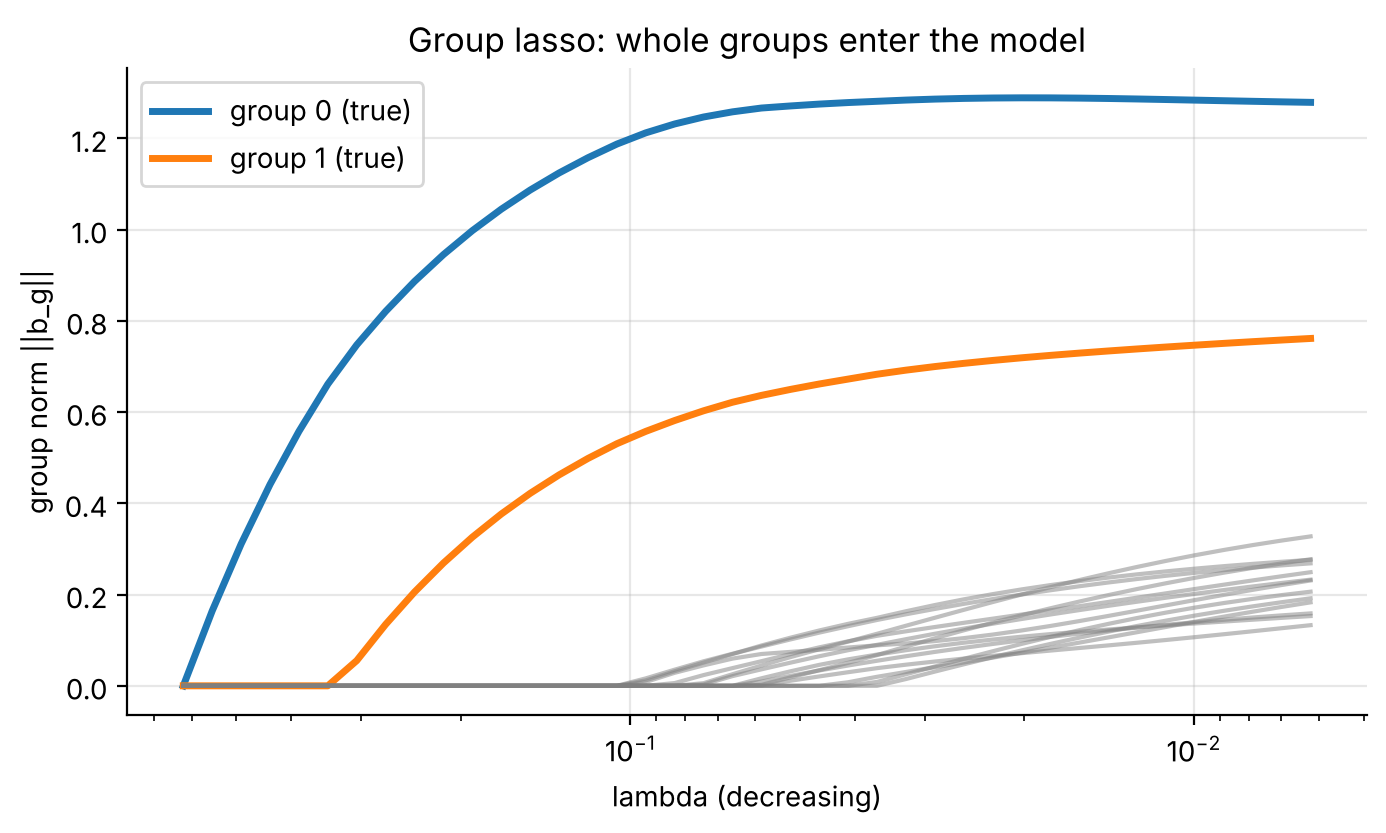

In [3]:
from nowcast.models import _group_lasso_path, group_lambda_max
n, n_groups, size = 150, 15, 6
groups = np.repeat(np.arange(n_groups), size)
X = rng.normal(size=(n, n_groups * size)); X = (X - X.mean(0)) / X.std(0)
beta = np.zeros(n_groups * size); beta[:6] = [1, .8, .5, .3, .2, .1]; beta[6:12] = [-.6, -.6, -.4, 0, 0, 0]
y = X @ beta + rng.normal(size=n); y -= y.mean()
lmax = group_lambda_max(X, y, groups)
lams = lmax * np.logspace(0, -2, 40)
path = _group_lasso_path(X, y, groups, lams)
norms = np.array([[np.linalg.norm(b[groups == g]) for g in range(n_groups)] for b in path])
plt.semilogx(lams, norms[:, :2], lw=2.5, label=["group 0 (true)", "group 1 (true)"])
plt.semilogx(lams, norms[:, 2:], c="grey", alpha=0.5)
plt.gca().invert_xaxis(); plt.xlabel("lambda (decreasing)"); plt.ylabel("group norm ||b_g||")
plt.legend(); plt.title("Group lasso: whole groups enter the model");

**Variants worth knowing**
* *Sparse group lasso* adds an L1 term to drop individual lags inside a selected group.
* *Overlapping group lasso* lets variables belong to several groups.

**Key takeaways**
* Adaptive lasso: less bias on big effects, cleaner selection; needs a decent first stage.
* Group lasso: selection at the level of a natural unit (an indicator, a dummy set, a spline basis).